In [30]:

import pandas as pd
import os

# Find CSV file
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename.endswith('.csv'):
            print(os.path.join(dirname, filename))

/kaggle/input/datasets/komalmuzaffar/netflix-data/NetFlix.csv


In [31]:

%matplotlib inline

import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.figsize"] = (10, 6)

In [32]:

import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from sklearn.preprocessing import LabelEncoder

# 1. Load dataset
csv_files = []

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename.endswith('.csv'):
            csv_files.append(os.path.join(dirname, filename))

if not csv_files:
    raise FileNotFoundError("No CSV file found in /kaggle/input")

df = pd.read_csv(csv_files[0])

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# 2. Clean dataset
df = df.drop_duplicates()
df = df.dropna()

# 3. Select target column
# Predict Sleep_Quality_Score
target = 'Sleep_Quality_Score'

if target not in df.columns:
    raise ValueError(
        f"Target column not found. Available columns: {df.columns.tolist()}"
    )

# 4. Prepare features and target
X = df.drop(columns=[target])
y = df[target]

# Encode categorical columns
X = pd.get_dummies(X, drop_first=True)

# Convert continuous sleep scores into classes if needed
if y.nunique() > 15:
    y = pd.cut(
        y,
        bins=3,
        labels=['Low', 'Medium', 'High']
    )

# Encode target if it contains text
if y.dtype == 'object' or isinstance(y.dtype, pd.CategoricalDtype):
    y = LabelEncoder().fit_transform(y)

# 5. Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# 6. Train Decision Tree
model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42,
    class_weight='balanced'
)

model.fit(X_train, y_train)

# 7. Predictions
y_pred = model.predict(X_test)

# 8. Evaluation
print("\nDecision Tree Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# 9. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

# 10. Decision Tree Graph
plt.figure(figsize=(24, 12))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Decision Tree for Sleep Quality Prediction")
plt.show()

# 11. Feature Importance
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False).head(10)

importance.sort_values().plot(
    kind='barh',
    figsize=(9, 6),
    color='teal'
)
plt.title("Top 10 Important Features")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

Dataset loaded successfully!
Dataset shape: (7787, 12)

Columns:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'genres', 'description']


ValueError: Target column not found. Available columns: ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'genres', 'description']

In [ ]:

import os

print("Input folder exists:", os.path.exists("/kaggle/input"))
print("Input folder contents:")

for root, dirs, files in os.walk("/kaggle/input"):
    print("Folder:", root)
    print("Files:", files)
    

In [ ]:
import os

print("Input folder exists:", os.path.exists("/kaggle/input"))
print("Input folder contents:")

for root, dirs, files in os.walk("/kaggle/input"):
    print("Folder:", root)
    print("Files:", files)

In [ ]:

import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

In [ ]:

# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder

# 2. Load Netflix dataset
path = "/kaggle/input/datasets/komalmuzaffar/netflix-data/NetFlix.csv"
df = pd.read_csv(path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

# 3. Clean data
df = df.drop_duplicates()
df = df.dropna()

# 4. Display dataset
display(df.head())

# 5. Select target column automatically
# Prefer a categorical column suitable for classification
possible_targets = [
    "type", "Type", "rating", "Rating",
    "listed_in", "country", "release_year"
]

target = next(
    (col for col in possible_targets if col in df.columns),
    None
)

if target is None:
    raise ValueError(
        "Choose a target column from: " + str(df.columns.tolist())
    )

print("\nTarget column:", target)

# 6. Prepare X and y
X = df.drop(columns=[target]).copy()
y = df[target].astype(str)

# Remove columns that could identify individual records
# and columns with too many unique values
drop_cols = [
    col for col in X.columns
    if X[col].nunique() > 100
    or X[col].nunique() / len(X) > 0.5
]
X = X.drop(columns=drop_cols)

# Encode categorical input features
X = pd.get_dummies(X, drop_first=True)

# Keep target classes with at least 2 examples
counts = y.value_counts()
valid_classes = counts[counts >= 2].index

mask = y.isin(valid_classes)
X = X.loc[mask]
y = y.loc[mask]

if y.nunique() < 2:
    raise ValueError("Not enough target classes to train the model.")

# Encode target labels
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# 7. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# 8. Train Decision Tree
model = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=5,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

# 9. Predictions and accuracy
y_pred = model.predict(X_test)

print("\nDecision Tree Accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=range(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

# 10. Confusion matrix
cm = confusion_matrix(
    y_test, y_pred,
    labels=range(len(encoder.classes_))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)
plt.title("Netflix Decision Tree - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 11. Visualize Decision Tree
plt.figure(figsize=(24, 12))
plot_tree(
    model,
    feature_names=X.columns.tolist(),
    class_names=encoder.classes_.tolist(),
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Netflix Decision Tree Classifier")
plt.show()

# 12. Top feature importance
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False).head(10)

importance.sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)
plt.title("Top 10 Important Features")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()


import pandas as pd

df = pd.read_csv(
    "/kaggle/input/datasets/komalmuzaffar/netflix-data/NetFlix.csv"
)

print(df.columns.tolist())
print(df.head(5))

In [ ]:

import pandas as pd

df = pd.read_csv(
    "/kaggle/input/datasets/komalmuzaffar/netflix-data/NetFlix.csv"
)

print(df.columns.tolist())
print(df.head(5))

In [ ]:

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [ ]:

plt.figure(figsize=(24, 12))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.tight_layout()
plt.show()

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.bar(
    ["Movie", "TV Show"],
    [70, 30]
)
plt.title("Test Graph")
plt.xlabel("Content Type")
plt.ylabel("Example Count")
plt.show()

In [ ]:

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

print("Checking model...")

print("Model:", model)
print("Features:", len(X.columns))

plt.figure(figsize=(24, 12))

plot_tree(
    model,
    feature_names=X.columns.tolist(),
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Netflix Decision Tree")
plt.tight_layout()
plt.show()

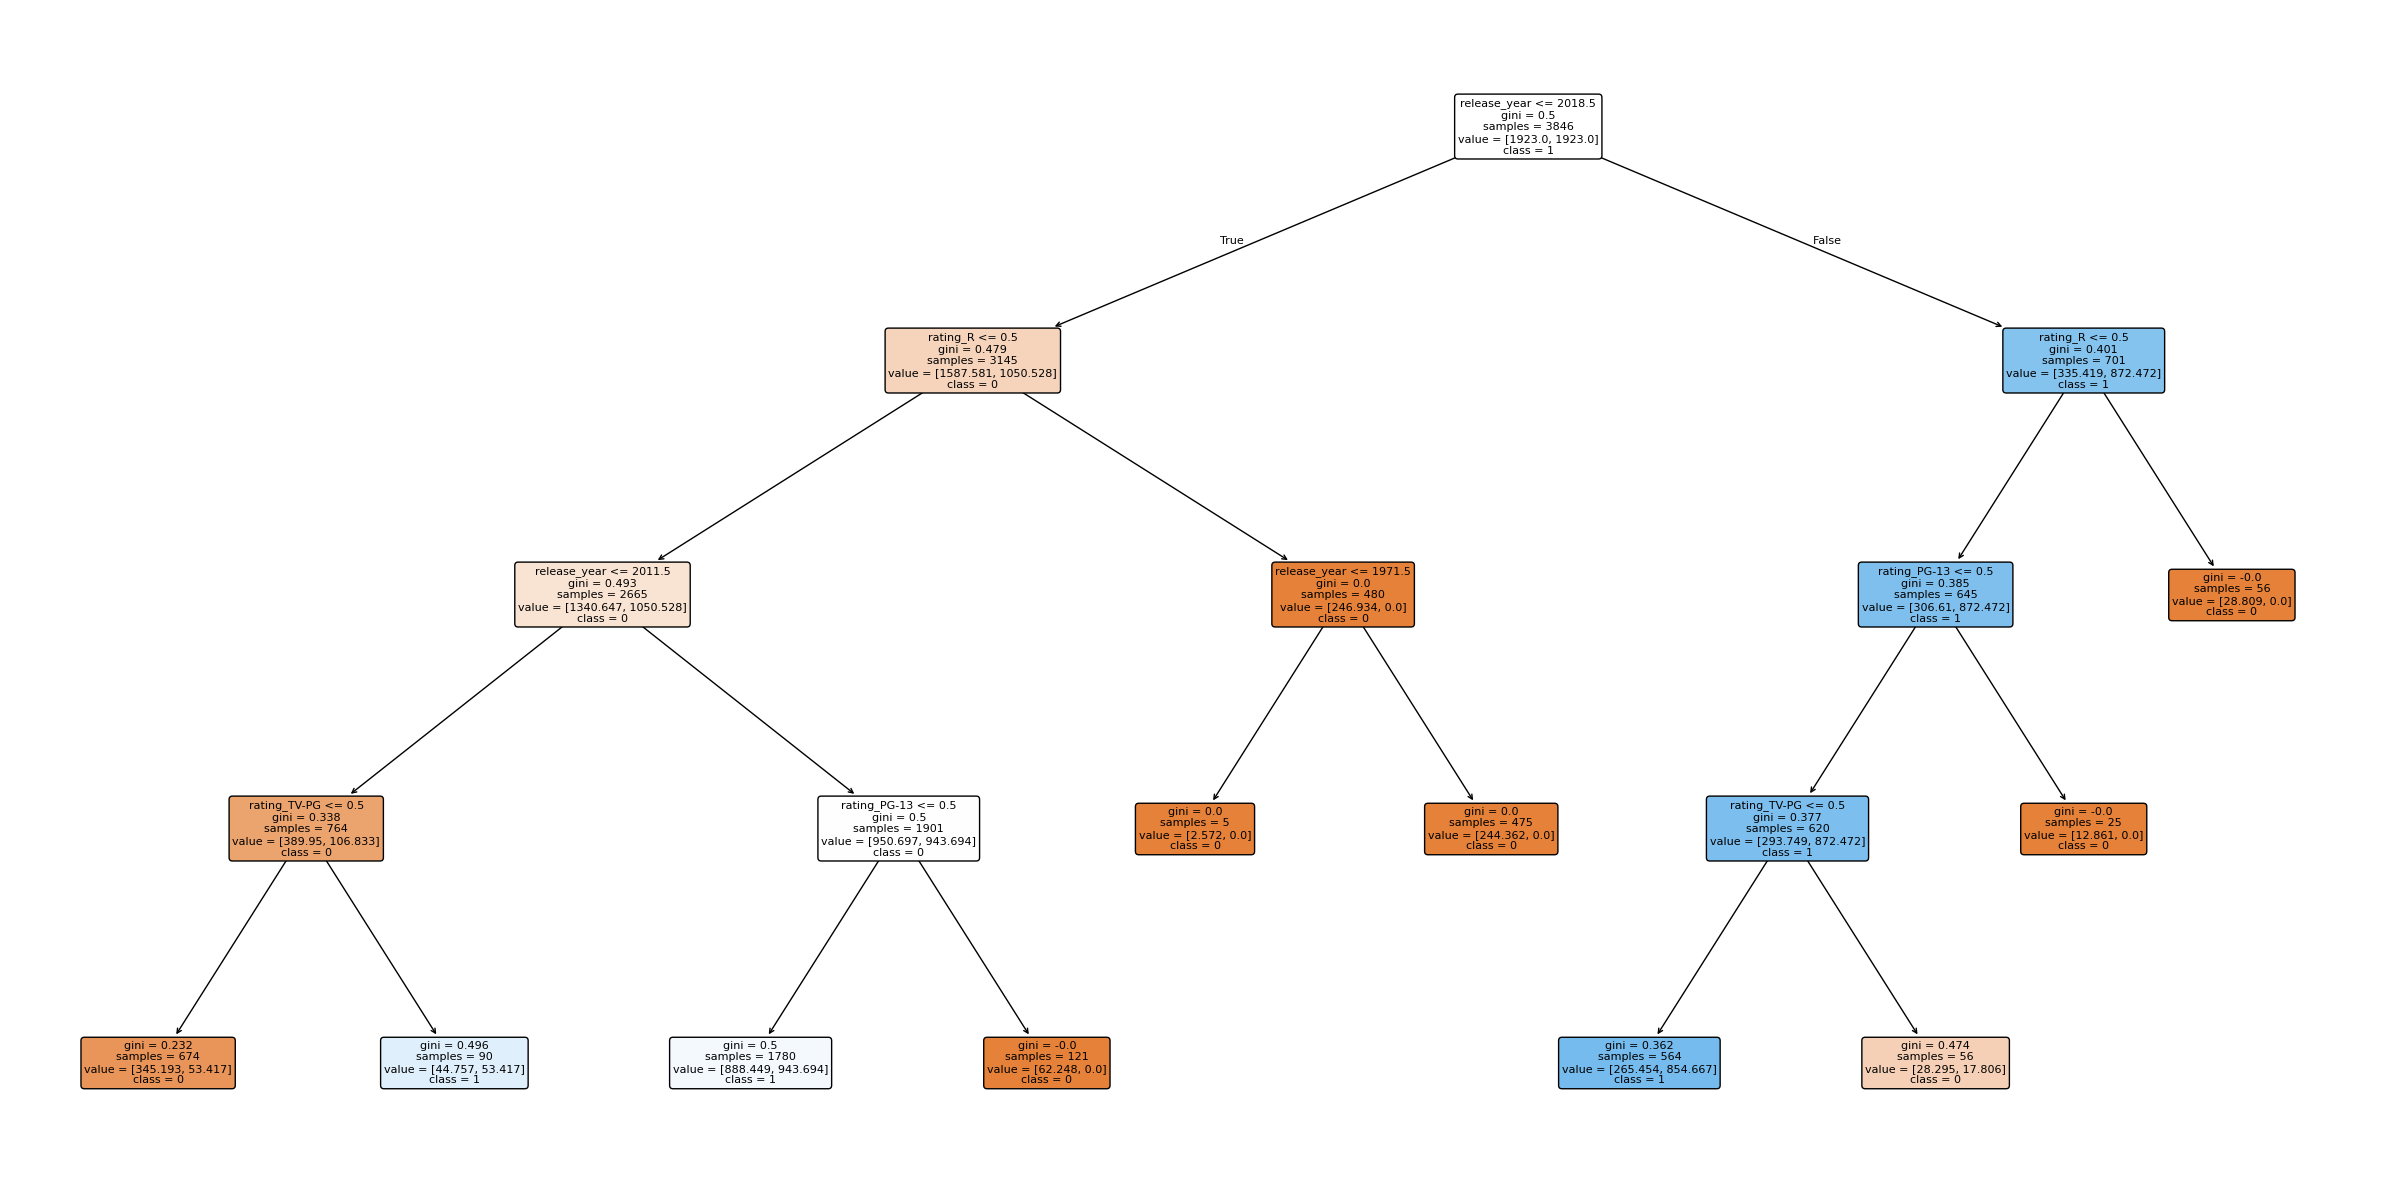

In [33]:
plt.figure(figsize=(24, 12))

plot_tree(
    model,
    feature_names=X.columns.tolist(),
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.tight_layout()
plt.savefig(
    "/kaggle/working/netflix_decision_tree.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

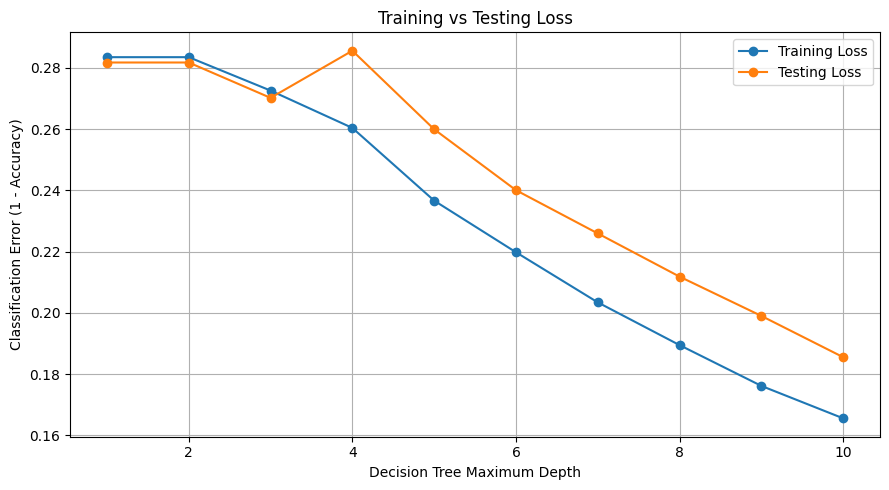

Best Tree Depth: 10
Training Accuracy: 83.45%
Testing Accuracy: 81.45%

Classification Report:
              precision    recall  f1-score   support

       Movie       0.85      0.89      0.87      1076
     TV Show       0.73      0.64      0.68       482

    accuracy                           0.81      1558
   macro avg       0.79      0.77      0.78      1558
weighted avg       0.81      0.81      0.81      1558



In [1]:

import os
import glob
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Find the dataset
files = glob.glob("/kaggle/input/**/NetFlix.csv", recursive=True)

if not files:
    raise FileNotFoundError(
        "NetFlix.csv not found. Add your dataset in Kaggle Input."
    )

df = pd.read_csv(files[0])
df = df.dropna(subset=["type"])

# Predict whether a title is a Movie or TV Show
X = df[["release_year", "rating", "country", "genres"]]
y = df["type"]

numeric_features = ["release_year"]
categorical_features = ["rating", "country", "genres"]

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Compare different tree depths
depths = range(1, 11)
train_losses = []
test_losses = []

for depth in depths:
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=depth, random_state=42
        ))
    ])

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_losses.append(1 - accuracy_score(y_train, train_pred))
    test_losses.append(1 - accuracy_score(y_test, test_pred))

# Plot training and testing error
plt.figure(figsize=(9, 5))
plt.plot(list(depths), train_losses, marker="o",
         label="Training Loss")
plt.plot(list(depths), test_losses, marker="o",
         label="Testing Loss")

plt.xlabel("Decision Tree Maximum Depth")
plt.ylabel("Classification Error (1 - Accuracy)")
plt.title("Training vs Testing Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Train final model using the best depth on the test-loss curve
best_depth = list(depths)[test_losses.index(min(test_losses))]

final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=best_depth, random_state=42
    ))
])

final_model.fit(X_train, y_train)

train_accuracy = accuracy_score(
    y_train, final_model.predict(X_train)
)
test_accuracy = accuracy_score(
    y_test, final_model.predict(X_test)
)

print("Best Tree Depth:", best_depth)
print(f"Training Accuracy: {train_accuracy:.2%}")
print(f"Testing Accuracy: {test_accuracy:.2%}")
print("\nClassification Report:")
print(classification_report(
    y_test, final_model.predict(X_test), zero_division=0
))


In [51]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

model = joblib.load("netflix_model.pkl")

st.title("Netflix Decision Tree Classifier")
st.write("Predict whether a title is a Movie or TV Show.")

release_year = st.number_input(
    "Release Year", min_value=1900,
    max_value=2035, value=2020
)

rating = st.selectbox(
    "Rating", ["TV-MA", "TV-14", "TV-PG", "PG-13", "R", "PG"]
)

country = st.text_input("Country")
genres = st.text_input("Genres")

if st.button("Predict"):
    data = pd.DataFrame([{
        "release_year": release_year,
        "rating": rating,
        "country": country,
        "genres": genres
    }])

    prediction = model.predict(data)[0]
    st.success(f"Prediction: {prediction}")

Overwriting app.py


In [52]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [53]:
!python -m streamlit --version

Streamlit, version 1.66.0


In [54]:
import os

print(os.listdir())

['.virtual_documents', 'app.py', 'netflix_decision_tree_model.pkl', 'netflix_model.pkl']


In [ ]:
!python -m streamlit run app.py



2026-10-16 06:50:57.812 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.19.2.2:8501
  External URL: http://136.86.249.68:8501

